
WEEK 1: RAW DATA INSPECTION
Shape: (7043, 21)
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object

Nulls (isnull) in raw:
 Series([], dtype: int64)
Blank-string TotalCharges count: 11
Full-row duplicates: 0 | Duplicate customerIDs: 0

NaN after to_numeric: 11
Rows with NaN TotalCharges (tenure, MonthlyCharges, Churn):
      customerID  tenure  MonthlyCharges Churn
488   4472-LVYGI       0           52.55    No
753   3115-CZMZD       0           20.25    No
93

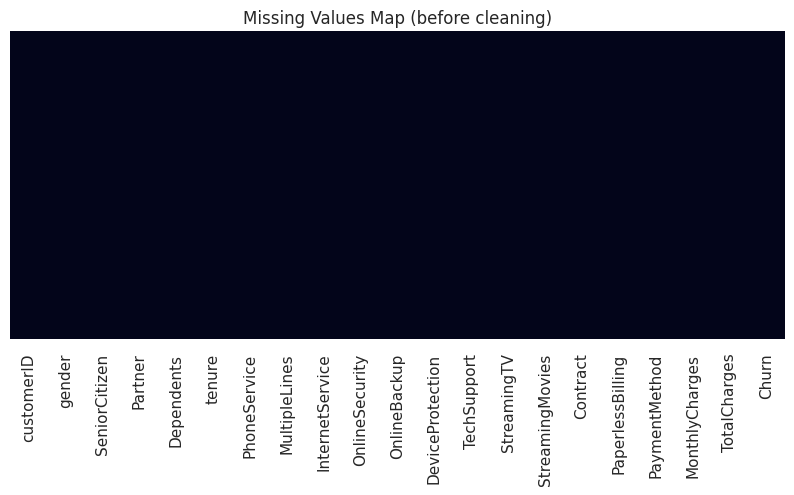

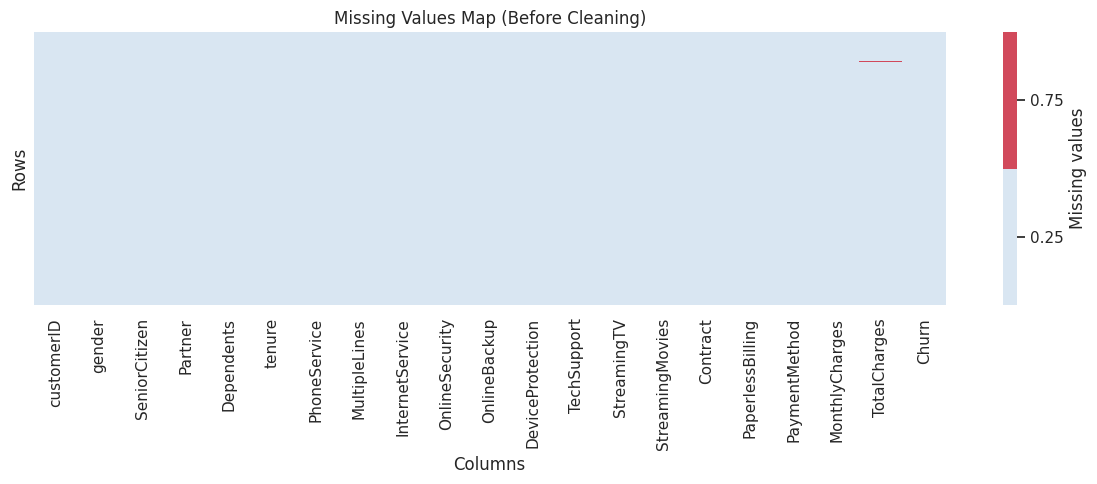

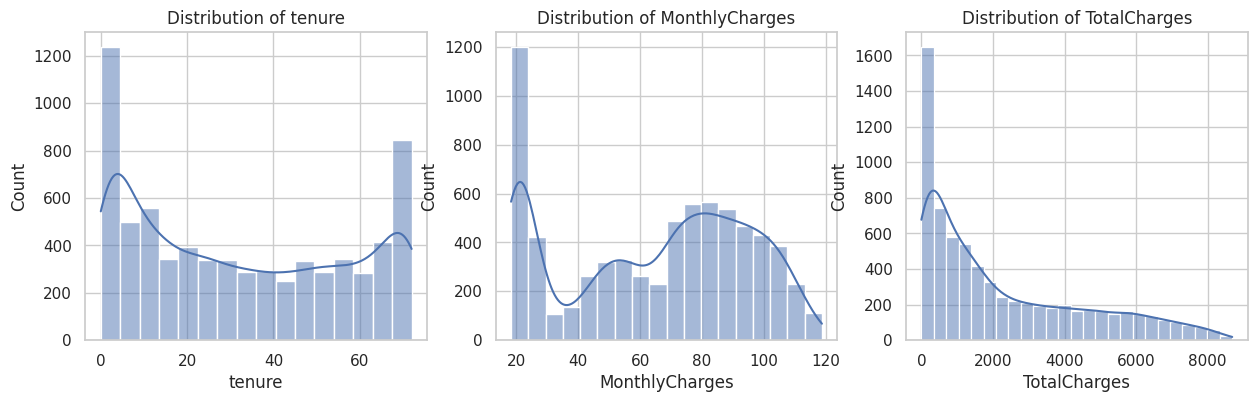

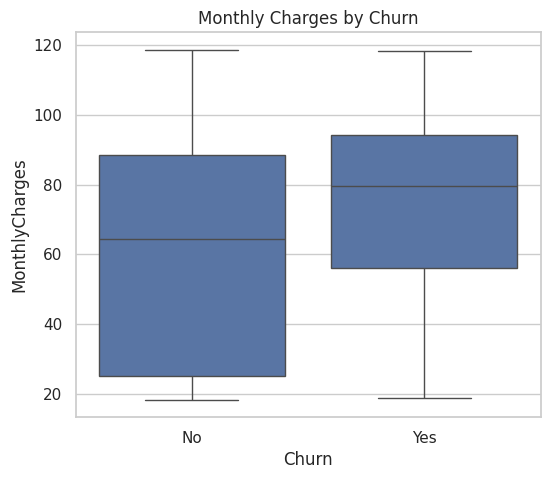

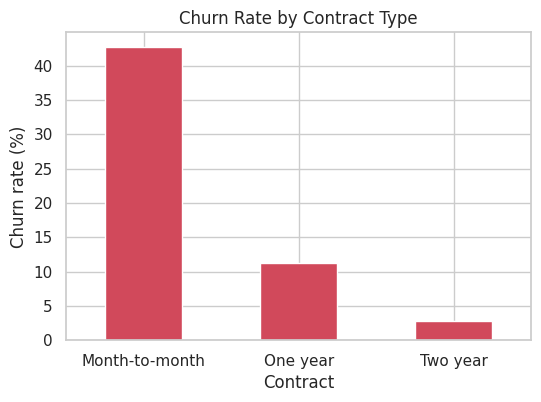

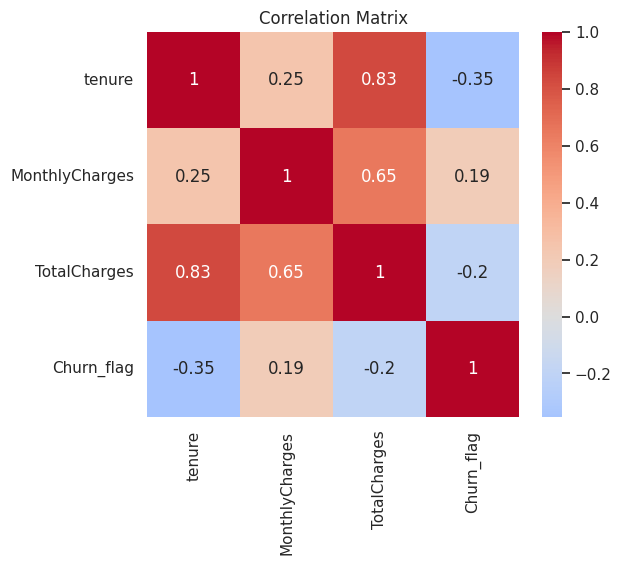


WEEK 2: STORY NUMBERS
Churn % by tenure band:
 tenure_band
0-6      52.94
7-12     35.89
13-24    28.71
25-48    20.39
49-72     9.51

Churn % by contract:
 Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83

Churn % InternetService x Contract:
 Contract         Month-to-month  One year  Two year
InternetService                                    
DSL                        32.2       9.3       1.9
Fiber optic                54.6      19.3       7.2
No                         18.9       2.5       0.8

Mean MonthlyCharges by churn: {'No': 61.27, 'Yes': 74.44}

Add-on churn % (internet customers):
                   Has service  No service
Service                                  
OnlineSecurity          14.61       41.77
TechSupport             15.17       41.64
OnlineBackup            21.53       39.93
DeviceProtection        22.50       39.13


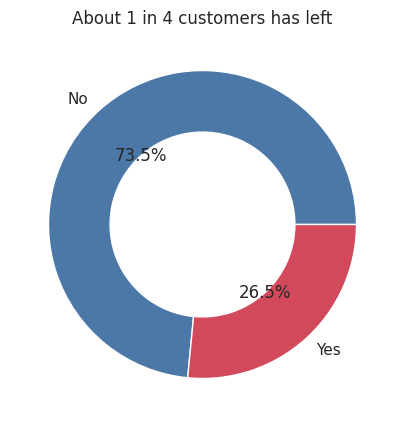

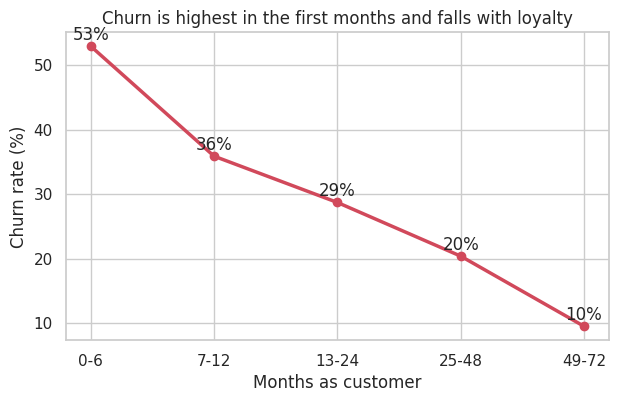

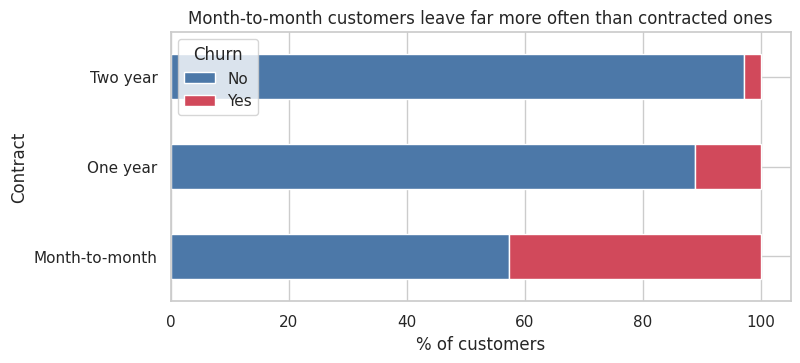

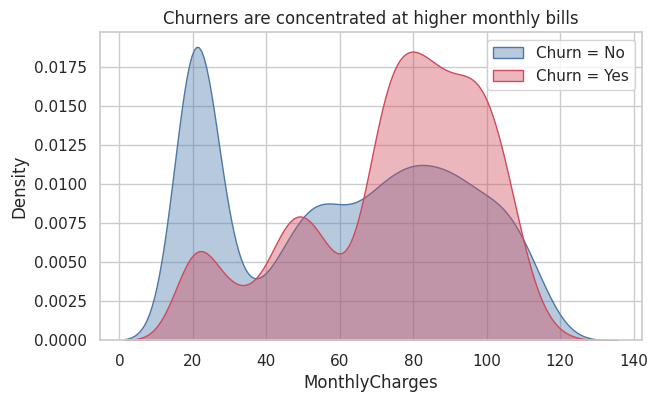

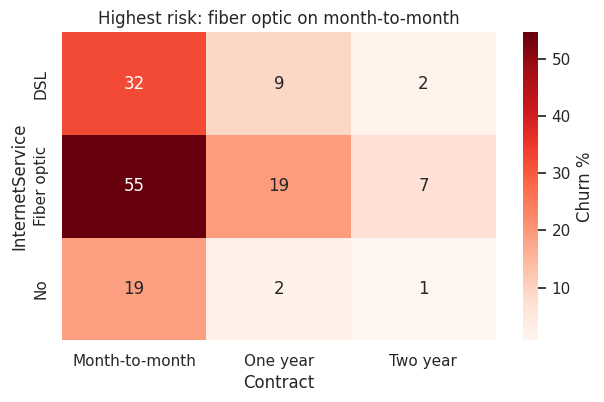

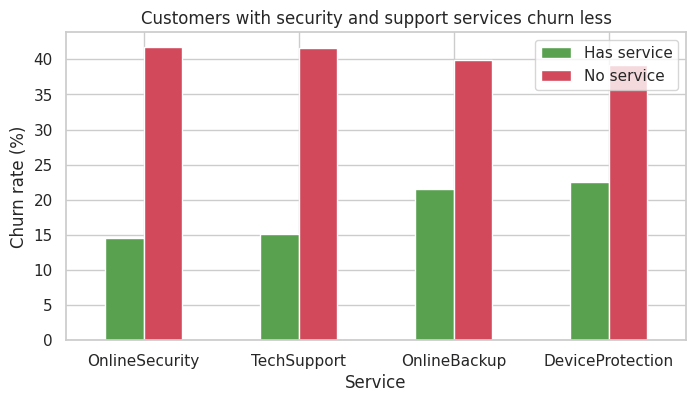

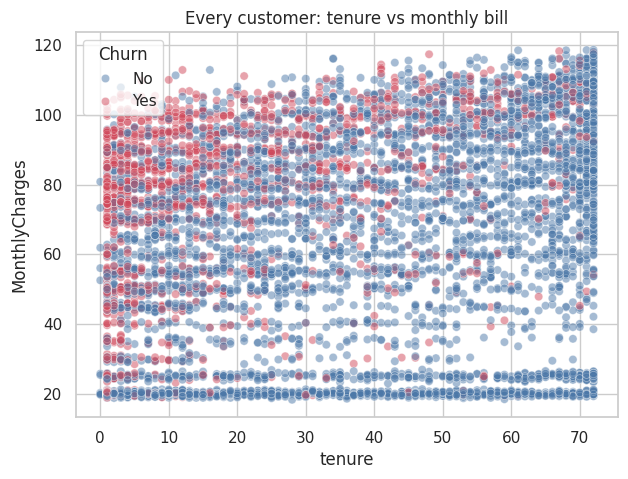


WEEK 3: HYPOTHESIS TESTS (alpha = 0.05, Bonferroni = 0.0125)
H1: mean churned = 74.44 (sd 24.67, n=1869), retained = 61.27 (sd 31.09, n=5174)
Shapiro-type normality (D'Agostino) churned: NormaltestResult(statistic=np.float64(150.4164578630375), pvalue=np.float64(2.1751097809888962e-33)) retained: NormaltestResult(statistic=np.float64(103168.89432198515), pvalue=np.float64(0.0))
Levene: LeveneResult(statistic=np.float64(361.8444859598828), pvalue=np.float64(1.0261244899421871e-78))
Welch t = 18.4075, p = 8.592e-73
Diff = 13.176, 95% CI = (11.773, 14.580), Cohen's d = 0.446, Welch dof = 4135.8
Mann-Whitney: MannwhitneyuResult(statistic=np.float64(6003125.5), pvalue=np.float64(3.311627651988585e-54))

H2: Contract x Churn
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48
chi2 = 1184.597, dof = 2, p = 5.863e-258, min expected = 390.9
Cramer's V = 0.4101
Row %:
 Churn              No    Yes
Contract       

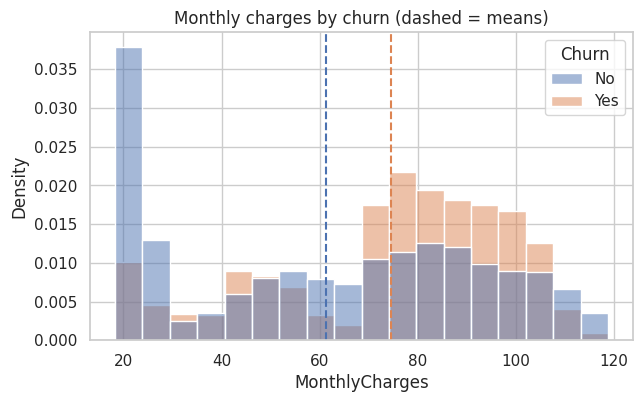

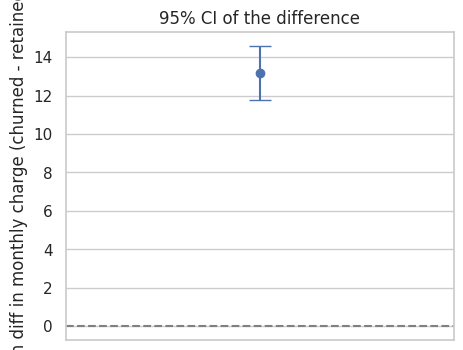

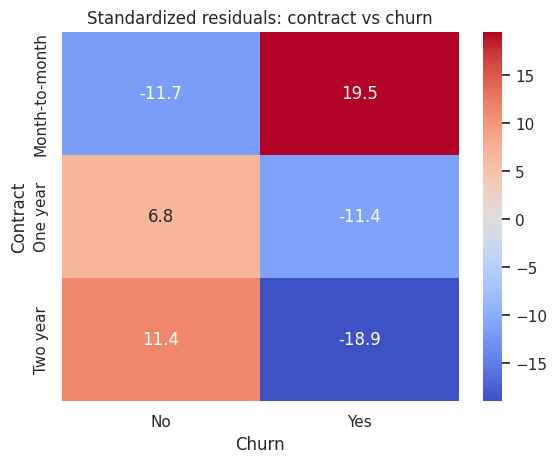

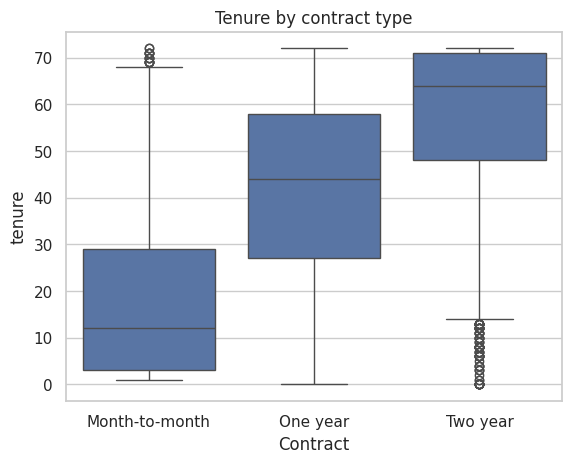


WEEK 4: MODELLING
Train/test sizes: 5634 1409 | churn rate train/test: 0.2654 0.2654
Baseline accuracy (predict all 'No'): 0.7346
Logistic Regression: CV AUC = 0.846 +/- 0.012
Decision Tree: CV AUC = 0.828 +/- 0.013
Random Forest: CV AUC = 0.848 +/- 0.010

                      Accuracy  Precision  Recall     F1  ROC-AUC  Train acc  CV AUC
Model                                                                              
Logistic Regression     0.739      0.505   0.786  0.615    0.842      0.753   0.846
Decision Tree           0.756      0.527   0.791  0.632    0.835      0.758   0.828
Random Forest           0.763      0.538   0.765  0.631    0.845      0.802   0.848
Logistic Regression confusion: TN=747 FP=288 FN=80 TP=294 | FPR=0.278 FNR=0.214
Decision Tree confusion: TN=769 FP=266 FN=78 TP=296 | FPR=0.257 FNR=0.209
Random Forest confusion: TN=789 FP=246 FN=88 TP=286 | FPR=0.238 FNR=0.235

Logistic Regression report:
               precision    recall  f1-score   support

        

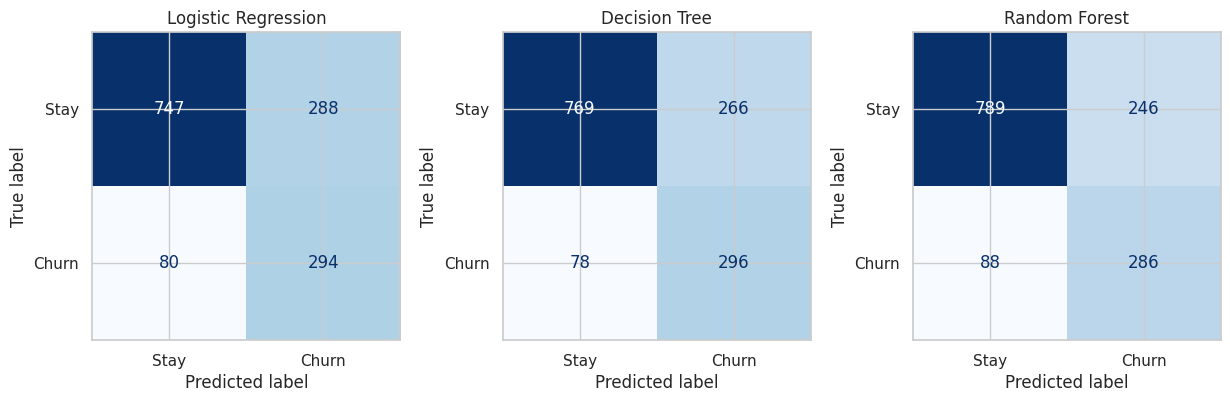

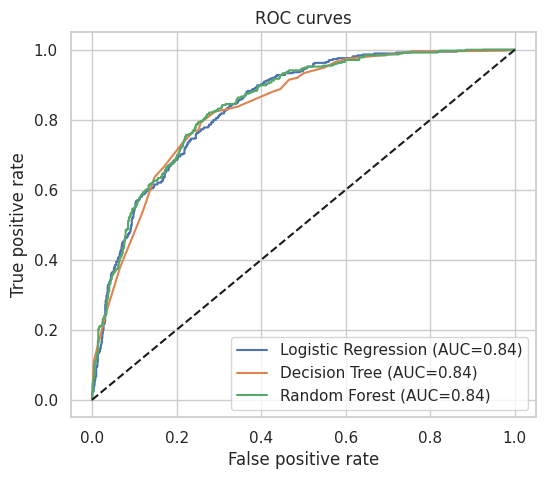

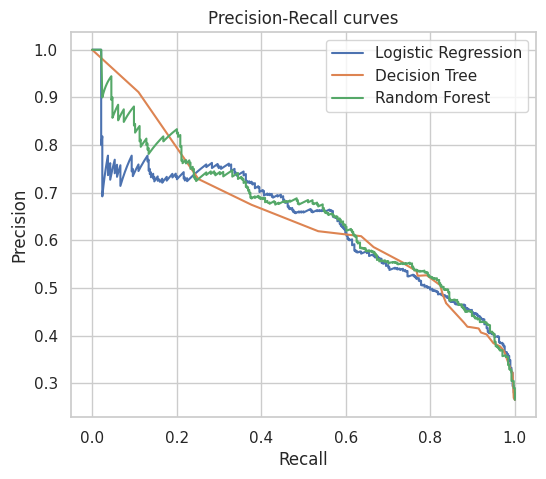

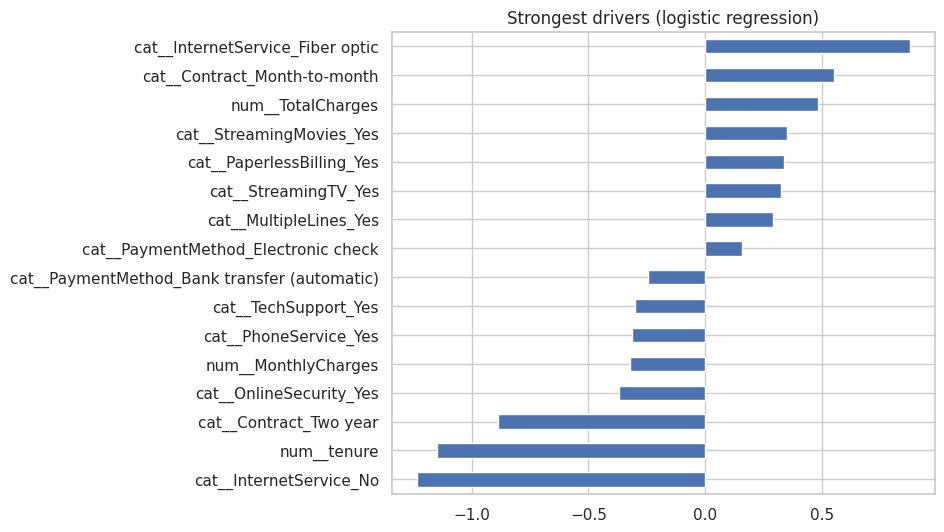

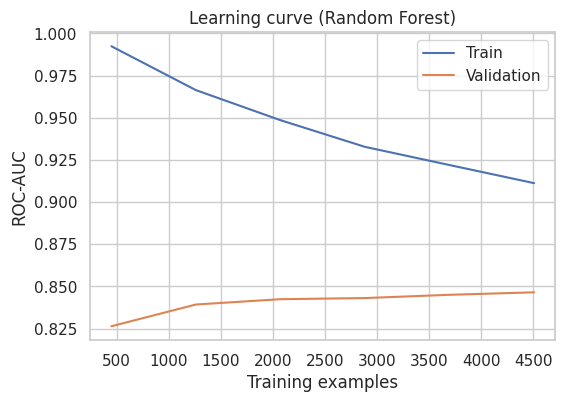

Learning curve final train/val AUC: 0.911 0.847

WEEK 5: BUSINESS IMPACT NUMBERS
Customers: 7043 | churned: 1869 (26.54%)
Avg monthly charge churned / retained: 74.44 61.27
Monthly revenue lost: 139130.85 | Annual recurring revenue lost: 1669570.2
  10% fewer churners -> 186 customers, annual revenue retained = 166,957
  20% fewer churners -> 373 customers, annual revenue retained = 333,914
  30% fewer churners -> 560 customers, annual revenue retained = 500,871
Share of churners on month-to-month: 88.6 %
Share of churners with tenure <= 12: 55.5 %
Share of churners on fiber: 69.4 %
Share of churners paying by electronic check: 57.3 %
High-risk segment (M2M + fiber + tenure<=12): n=916, churn rate=70.2%
M2M + electronic check: n=1850, churn rate=53.7%
Share of customers on month-to-month: 55.0 %


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


DONE. Copy ALL the text output above and paste it to Claude.


In [9]:
import warnings; warnings.filterwarnings("ignore")
import os, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve, classification_report)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
os.makedirs("figs", exist_ok=True)
def H(t): print("\n" + "="*75 + "\n" + t + "\n" + "="*75)
def save(name):
    plt.savefig(f"figs/{name}.png", dpi=200, bbox_inches="tight"); plt.show()

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
raw = pd.read_csv(URL)

# ============================ WEEK 1 ============================
H("WEEK 1: RAW DATA INSPECTION")
print("Shape:", raw.shape)
print(raw.dtypes.to_string())
print("\nNulls (isnull) in raw:\n", raw.isnull().sum()[raw.isnull().sum() > 0])
blank = (raw["TotalCharges"].astype(str).str.strip() == "")
print("Blank-string TotalCharges count:", blank.sum())
print("Full-row duplicates:", raw.duplicated().sum(), "| Duplicate customerIDs:", raw["customerID"].duplicated().sum())

df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("\nNaN after to_numeric:", df["TotalCharges"].isnull().sum())
print("Rows with NaN TotalCharges (tenure, MonthlyCharges, Churn):")
print(df[df["TotalCharges"].isnull()][["customerID","tenure","MonthlyCharges","Churn"]].to_string())
print("Tenure values among those rows:", df[df["TotalCharges"].isnull()]["tenure"].unique())

df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0:"No", 1:"Yes"})
obj_cols = df.select_dtypes("object").columns
df[obj_cols] = df[obj_cols].apply(lambda s: s.str.strip())
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)
print("\nNulls after cleaning:", df.isnull().sum().sum())
print("Unique values of categorical columns:")
for c in obj_cols.drop("customerID"):
    print(f"  {c}: {list(df[c].unique())}")

H("WEEK 1: OUTLIERS (IQR rule)")
for col in ["tenure","MonthlyCharges","TotalCharges"]:
    q1, q3 = df[col].quantile([.25,.75]); iqr = q3 - q1
    n = ((df[col] < q1-1.5*iqr) | (df[col] > q3+1.5*iqr)).sum()
    print(f"{col}: IQR outliers = {n}, skew = {df[col].skew():.3f}")

H("WEEK 1: SUMMARY STATISTICS")
print(df[["tenure","MonthlyCharges","TotalCharges"]].describe().round(2).to_string())
print("\nMedian:", df[["tenure","MonthlyCharges","TotalCharges"]].median().round(2).to_dict())
print("\nChurn counts:\n", df["Churn"].value_counts().to_string())
print("Churn %:\n", (df["Churn"].value_counts(normalize=True)*100).round(2).to_string())
print("\nCorrelation matrix:\n", df[["tenure","MonthlyCharges","TotalCharges","Churn_flag"]].corr().round(3).to_string())

H("WEEK 1: CHURN RATE (%) BY CATEGORY")
for c in ["Contract","InternetService","PaymentMethod","TechSupport","OnlineSecurity","SeniorCitizen",
          "Partner","Dependents","gender","PaperlessBilling","StreamingTV","MultipleLines"]:
    print(f"\n{c}:\n", (df.groupby(c)["Churn_flag"].mean()*100).round(2).to_string())

df.to_csv("telco_clean.csv", index=False)

# W1 figures
plt.figure(figsize=(10,4)); r2 = raw.copy(); r2["TotalCharges"] = pd.to_numeric(r2["TotalCharges"], errors="coerce")
sns.heatmap(r2.isnull(), cbar=False, yticklabels=False); plt.title("Missing Values Map (before cleaning)"); save("w1_fig1_missing")

# Missing values map before cleaning
plt.figure(figsize=(12, 5))

r2 = raw.copy()
r2["TotalCharges"] = pd.to_numeric(
    r2["TotalCharges"], errors="coerce"
)

sns.heatmap(
    r2.isnull(),
    cmap=["#d9e6f2", "#d1495b"],
    cbar=True,
    yticklabels=False,
    cbar_kws={
        "ticks": [0.25, 0.75],
        "label": "Missing values"
    }
)

plt.title("Missing Values Map (Before Cleaning)")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.xticks(rotation=90)
plt.tight_layout()

save("w1_fig1_missing")

fig, ax = plt.subplots(1,3, figsize=(15,4))
for a, col in zip(ax, ["tenure","MonthlyCharges","TotalCharges"]):
    sns.histplot(df[col], kde=True, ax=a); a.set_title(f"Distribution of {col}")
save("w1_fig2_hist")
plt.figure(figsize=(6,5)); sns.boxplot(data=df, x="Churn", y="MonthlyCharges"); plt.title("Monthly Charges by Churn"); save("w1_fig3_box")
(df.groupby("Contract")["Churn_flag"].mean()*100).plot(kind="bar", figsize=(6,4), color="#d1495b")
plt.ylabel("Churn rate (%)"); plt.title("Churn Rate by Contract Type"); plt.xticks(rotation=0); save("w1_fig4_contract")
plt.figure(figsize=(6,5)); sns.heatmap(df[["tenure","MonthlyCharges","TotalCharges","Churn_flag"]].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Matrix"); save("w1_fig5_corr")

# ============================ WEEK 2 ============================
H("WEEK 2: STORY NUMBERS")
COL = {"Yes":"#d1495b", "No":"#4c78a8"}
df["tenure_band"] = pd.cut(df["tenure"], [-1,6,12,24,48,72], labels=["0-6","7-12","13-24","25-48","49-72"])
t = df.groupby("tenure_band", observed=True)["Churn_flag"].mean().mul(100)
print("Churn % by tenure band:\n", t.round(2).to_string())
print("\nChurn % by contract:\n", pd.crosstab(df["Contract"], df["Churn"], normalize="index").mul(100).round(2).to_string())
pv = df.pivot_table(index="InternetService", columns="Contract", values="Churn_flag", aggfunc="mean").mul(100)
print("\nChurn % InternetService x Contract:\n", pv.round(1).to_string())
print("\nMean MonthlyCharges by churn:", df.groupby("Churn")["MonthlyCharges"].mean().round(2).to_dict())
sub = df[df["InternetService"] != "No"]
rows = []
for s in ["OnlineSecurity","TechSupport","OnlineBackup","DeviceProtection"]:
    r = sub.groupby(s)["Churn_flag"].mean().mul(100)
    rows.append({"Service":s, "Has service":r.get("Yes"), "No service":r.get("No")})
svc_df = pd.DataFrame(rows).set_index("Service"); print("\nAdd-on churn % (internet customers):\n", svc_df.round(2).to_string())

counts = df["Churn"].value_counts()
fig, ax = plt.subplots(figsize=(5,5)); ax.pie(counts, labels=counts.index, colors=[COL[i] for i in counts.index], autopct="%1.1f%%", wedgeprops=dict(width=0.4))
ax.set_title("About 1 in 4 customers has left"); save("w2_v1_donut")
plt.figure(figsize=(7,4)); plt.plot(t.index.astype(str), t.values, marker="o", color=COL["Yes"], lw=2.5)
for x, y in zip(t.index.astype(str), t.values): plt.text(x, y+1, f"{y:.0f}%", ha="center")
plt.title("Churn is highest in the first months and falls with loyalty"); plt.ylabel("Churn rate (%)"); plt.xlabel("Months as customer"); save("w2_v2_tenure")
ct_ = pd.crosstab(df["Contract"], df["Churn"], normalize="index").mul(100)
ct_[["No","Yes"]].plot(kind="barh", stacked=True, color=[COL["No"],COL["Yes"]], figsize=(8,3.5))
plt.title("Month-to-month customers leave far more often than contracted ones"); plt.xlabel("% of customers"); save("w2_v3_contract")
plt.figure(figsize=(7,4))
for k, g in df.groupby("Churn"): sns.kdeplot(g["MonthlyCharges"], fill=True, alpha=.4, color=COL[k], label=f"Churn = {k}")
plt.title("Churners are concentrated at higher monthly bills"); plt.legend(); save("w2_v4_price")
plt.figure(figsize=(7,4)); sns.heatmap(pv, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label":"Churn %"})
plt.title("Highest risk: fiber optic on month-to-month"); save("w2_v5_heatmap")
svc_df.plot(kind="bar", figsize=(8,4), color=["#59a14f","#d1495b"]); plt.title("Customers with security and support services churn less")
plt.ylabel("Churn rate (%)"); plt.xticks(rotation=0); save("w2_v6_services")
plt.figure(figsize=(7,5)); sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", hue="Churn", palette=COL, alpha=.5)
plt.title("Every customer: tenure vs monthly bill"); save("w2_v7_scatter")
px.scatter(df, x="tenure", y="MonthlyCharges", color="Churn", color_discrete_map=COL, opacity=.6,
           hover_data=["Contract","InternetService"]).write_html("figs/w2_v7_interactive.html")

# ============================ WEEK 3 ============================
H("WEEK 3: HYPOTHESIS TESTS (alpha = 0.05, Bonferroni = 0.0125)")
a = df.loc[df.Churn=="Yes","MonthlyCharges"]; b = df.loc[df.Churn=="No","MonthlyCharges"]
print(f"H1: mean churned = {a.mean():.2f} (sd {a.std():.2f}, n={len(a)}), retained = {b.mean():.2f} (sd {b.std():.2f}, n={len(b)})")
print("Shapiro-type normality (D'Agostino) churned:", stats.normaltest(a), "retained:", stats.normaltest(b))
print("Levene:", stats.levene(a, b))
tt, p = stats.ttest_ind(a, b, equal_var=False); print(f"Welch t = {tt:.4f}, p = {p:.3e}")
diff = a.mean()-b.mean(); va, vb = a.var(ddof=1)/len(a), b.var(ddof=1)/len(b); se = np.sqrt(va+vb)
dof = (va+vb)**2/(va**2/(len(a)-1)+vb**2/(len(b)-1)); ci = (diff-stats.t.ppf(.975,dof)*se, diff+stats.t.ppf(.975,dof)*se)
sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2))
print(f"Diff = {diff:.3f}, 95% CI = ({ci[0]:.3f}, {ci[1]:.3f}), Cohen's d = {diff/sp:.3f}, Welch dof = {dof:.1f}")
print("Mann-Whitney:", stats.mannwhitneyu(a, b, alternative="two-sided"))

ctab = pd.crosstab(df["Contract"], df["Churn"]); chi2, p, dofc, exp_c = stats.chi2_contingency(ctab)
print(f"\nH2: Contract x Churn\n{ctab.to_string()}\nchi2 = {chi2:.3f}, dof = {dofc}, p = {p:.3e}, min expected = {exp_c.min():.1f}")
print(f"Cramer's V = {np.sqrt(chi2/(ctab.values.sum()*(min(ctab.shape)-1))):.4f}")
print("Row %:\n", ctab.div(ctab.sum(axis=1), axis=0).mul(100).round(2).to_string())

groups = [g["tenure"].values for _, g in df.groupby("Contract")]
print("\nH3: tenure by contract. Means:", df.groupby("Contract")["tenure"].mean().round(2).to_dict())
print("Levene:", stats.levene(*groups)); F, p = stats.f_oneway(*groups); print(f"ANOVA F = {F:.3f}, p = {p:.3e}")
aov = sm.stats.anova_lm(ols("tenure ~ C(Contract)", data=df).fit(), typ=2); print(aov.round(4).to_string())
print(f"eta squared = {aov['sum_sq'].iloc[0]/aov['sum_sq'].sum():.4f}")
print(pairwise_tukeyhsd(df["tenure"], df["Contract"]).summary())
print("Kruskal-Wallis:", stats.kruskal(*groups))

ct2 = pd.crosstab(df["PaymentMethod"], df["Churn"]); chi2b, pb, dofb, _ = stats.chi2_contingency(ct2)
print(f"\nH4: Payment x Churn\nchi2 = {chi2b:.3f}, dof = {dofb}, p = {pb:.3e}, Cramer's V = {np.sqrt(chi2b/(ct2.values.sum()*(min(ct2.shape)-1))):.4f}")
print("Row %:\n", ct2.div(ct2.sum(axis=1), axis=0).mul(100).round(2).to_string())

# W3 figures
plt.figure(figsize=(7,4)); sns.histplot(data=df, x="MonthlyCharges", hue="Churn", stat="density", common_norm=False, alpha=.5)
plt.axvline(a.mean(), color="C1", ls="--"); plt.axvline(b.mean(), color="C0", ls="--"); plt.title("Monthly charges by churn (dashed = means)"); save("w3_fig1_dist")
plt.figure(figsize=(5,4)); plt.errorbar([0],[diff], yerr=[[diff-ci[0]],[ci[1]-diff]], fmt="o", capsize=8); plt.axhline(0, color="gray", ls="--")
plt.xticks([]); plt.ylabel("Mean diff in monthly charge (churned - retained)"); plt.title("95% CI of the difference"); save("w3_fig2_ci")
resid = (ctab.values - exp_c)/np.sqrt(exp_c)
sns.heatmap(pd.DataFrame(resid, index=ctab.index, columns=ctab.columns), annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Standardized residuals: contract vs churn"); save("w3_fig3_resid")
sns.boxplot(data=df, x="Contract", y="tenure"); plt.title("Tenure by contract type"); save("w3_fig4_box")

# ============================ WEEK 4 ============================
H("WEEK 4: MODELLING")
d4 = df.drop(columns=["customerID","tenure_band"]).copy()
for c in ["MultipleLines","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]:
    d4[c] = d4[c].replace({"No internet service":"No","No phone service":"No"})
y = d4["Churn_flag"]; X = d4.drop(columns=["Churn","Churn_flag"])
num = ["tenure","MonthlyCharges","TotalCharges"]; cat = [c for c in X.columns if c not in num]
pre = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat)])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train/test sizes:", len(X_tr), len(X_te), "| churn rate train/test:", round(y_tr.mean(),4), round(y_te.mean(),4))
print("Baseline accuracy (predict all 'No'):", round(1-y_te.mean(),4))
models = {"Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
          "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
          "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42, n_jobs=-1)}
pipes = {n: Pipeline([("pre", pre), ("clf", m)]) for n, m in models.items()}
skf = StratifiedKFold(5, shuffle=True, random_state=42); rows = []
for n, p_ in pipes.items():
    cv = cross_val_score(p_, X_tr, y_tr, cv=skf, scoring="roc_auc"); p_.fit(X_tr, y_tr)
    pred = p_.predict(X_te); proba = p_.predict_proba(X_te)[:,1]
    print(f"{n}: CV AUC = {cv.mean():.3f} +/- {cv.std():.3f}")
    rows.append({"Model":n, "Accuracy":accuracy_score(y_te,pred), "Precision":precision_score(y_te,pred), "Recall":recall_score(y_te,pred),
                 "F1":f1_score(y_te,pred), "ROC-AUC":roc_auc_score(y_te,proba), "Train acc":accuracy_score(y_tr,p_.predict(X_tr)),
                 "CV AUC":cv.mean()})
res = pd.DataFrame(rows).set_index("Model").round(3); print("\n", res.to_string())
for n, p_ in pipes.items():
    tn, fp, fn, tp = confusion_matrix(y_te, p_.predict(X_te)).ravel()
    print(f"{n} confusion: TN={tn} FP={fp} FN={fn} TP={tp} | FPR={fp/(fp+tn):.3f} FNR={fn/(fn+tp):.3f}")
print("\nLogistic Regression report:\n", classification_report(y_te, pipes["Logistic Regression"].predict(X_te), target_names=["Stay","Churn"]))

lr = pipes["Logistic Regression"]; proba = lr.predict_proba(X_te)[:,1]
print("Threshold tuning (LR):")
for th in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pr_ = (proba >= th).astype(int)
    print(f"  t={th}: precision={precision_score(y_te,pr_):.3f} recall={recall_score(y_te,pr_):.3f} f1={f1_score(y_te,pr_):.3f}")
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["pre"].get_feature_names_out()).sort_values()
print("\nTop negative coefficients:\n", coef.head(8).round(3).to_string()); print("Top positive coefficients:\n", coef.tail(8).round(3).to_string())
print("Odds ratios (top 5 positive):\n", np.exp(coef.tail(5)).round(2).to_string())
rf_imp = pd.Series(pipes["Random Forest"].named_steps["clf"].feature_importances_, index=pipes["Random Forest"].named_steps["pre"].get_feature_names_out()).sort_values(ascending=False)
print("\nRandom Forest top 8 importances:\n", rf_imp.head(8).round(3).to_string())
gs = GridSearchCV(lr, {"clf__C":[0.01,0.1,1,10]}, cv=skf, scoring="roc_auc").fit(X_tr, y_tr)
print("\nGridSearch best params:", gs.best_params_, "best CV AUC:", round(gs.best_score_,4), "| test AUC:", round(roc_auc_score(y_te, gs.predict_proba(X_te)[:,1]),4))

fig, ax = plt.subplots(1,3, figsize=(15,4))
for a_, (n, p_) in zip(ax, pipes.items()):
    ConfusionMatrixDisplay.from_estimator(p_, X_te, y_te, ax=a_, cmap="Blues", display_labels=["Stay","Churn"], colorbar=False); a_.set_title(n)
save("w4_fig1_confusion")
plt.figure(figsize=(6,5))
for n, p_ in pipes.items():
    pb_ = p_.predict_proba(X_te)[:,1]; fpr, tpr, _ = roc_curve(y_te, pb_); plt.plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_te,pb_):.2f})")
plt.plot([0,1],[0,1],"k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.legend(); plt.title("ROC curves"); save("w4_fig2_roc")
plt.figure(figsize=(6,5))
for n, p_ in pipes.items():
    pr_, rc_, _ = precision_recall_curve(y_te, p_.predict_proba(X_te)[:,1]); plt.plot(rc_, pr_, label=n)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(); plt.title("Precision-Recall curves"); save("w4_fig3_pr")
pd.concat([coef.head(8), coef.tail(8)]).plot(kind="barh", figsize=(7,6)); plt.title("Strongest drivers (logistic regression)"); save("w4_fig4_coef")
sizes, trs, vas = learning_curve(pipes["Random Forest"], X_tr, y_tr, cv=5, scoring="roc_auc", train_sizes=np.linspace(.1,1,6), n_jobs=-1)
plt.figure(figsize=(6,4)); plt.plot(sizes, trs.mean(1), label="Train"); plt.plot(sizes, vas.mean(1), label="Validation")
plt.legend(); plt.xlabel("Training examples"); plt.ylabel("ROC-AUC"); plt.title("Learning curve (Random Forest)"); save("w4_fig5_learning")
print("Learning curve final train/val AUC:", round(trs.mean(1)[-1],3), round(vas.mean(1)[-1],3))

# ============================ WEEK 5 ============================
H("WEEK 5: BUSINESS IMPACT NUMBERS")
ch = df[df.Churn=="Yes"]
print("Customers:", len(df), "| churned:", len(ch), f"({len(ch)/len(df)*100:.2f}%)")
print("Avg monthly charge churned / retained:", round(ch["MonthlyCharges"].mean(),2), round(df[df.Churn=="No"]["MonthlyCharges"].mean(),2))
print("Monthly revenue lost:", round(ch["MonthlyCharges"].sum(),2), "| Annual recurring revenue lost:", round(ch["MonthlyCharges"].sum()*12,2))
for r in [0.10, 0.20, 0.30]:
    print(f"  {int(r*100)}% fewer churners -> {int(len(ch)*r)} customers, annual revenue retained = {ch['MonthlyCharges'].sum()*12*r:,.0f}")
print("Share of churners on month-to-month:", round((ch["Contract"]=="Month-to-month").mean()*100,1), "%")
print("Share of churners with tenure <= 12:", round((ch["tenure"]<=12).mean()*100,1), "%")
print("Share of churners on fiber:", round((ch["InternetService"]=="Fiber optic").mean()*100,1), "%")
print("Share of churners paying by electronic check:", round((ch["PaymentMethod"]=="Electronic check").mean()*100,1), "%")
seg = df[(df.Contract=="Month-to-month") & (df.InternetService=="Fiber optic") & (df.tenure<=12)]
print(f"High-risk segment (M2M + fiber + tenure<=12): n={len(seg)}, churn rate={seg['Churn_flag'].mean()*100:.1f}%")
seg2 = df[(df.Contract=="Month-to-month") & (df.PaymentMethod=="Electronic check")]
print(f"M2M + electronic check: n={len(seg2)}, churn rate={seg2['Churn_flag'].mean()*100:.1f}%")
print("Share of customers on month-to-month:", round((df.Contract=='Month-to-month').mean()*100,1), "%")

# package
df.to_csv("figs/telco_clean.csv", index=False)
with zipfile.ZipFile("churn_figures.zip", "w") as z:
    for f in os.listdir("figs"): z.write(f"figs/{f}")
try:
    from google.colab import files; files.download("churn_figures.zip")
except Exception: print("Zip saved as churn_figures.zip in the file panel.")
print("\nDONE. Copy ALL the text output above and paste it to Claude.")

Normality p churned: 2.1751097809888962e-33 | retained: 0.0
Monthly revenue lost: 139130.85 | Annual: 1669570.2
10% fewer churners -> 186 customers, annual revenue retained = 166,957
20% fewer churners -> 373 customers, annual revenue retained = 333,914
30% fewer churners -> 560 customers, annual revenue retained = 500,871
Churners on month-to-month %: 88.6
Churners with tenure<=12 %: 55.5
Churners on fiber %: 69.4
Churners paying electronic check %: 57.3
Segment M2M+fiber+tenure<=12: n=916, churn=70.2%
Segment M2M+echeck: n=1850, churn=53.7%
Mean monthly charge among internet customers, churned vs retained: {'No': 76.34, 'Yes': 77.92}
Learning curve sizes: [ 450 1261 2073 2884 3695 4507]
Train AUC: [0.992 0.966 0.949 0.933 0.922 0.911]
Val AUC: [0.826 0.839 0.842 0.843 0.845 0.847]


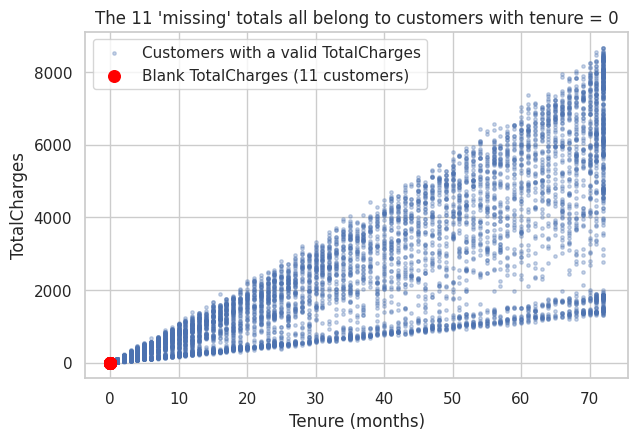

In [10]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
raw = pd.read_csv(URL); df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0:"No", 1:"Yes"})

# 1) full normality p-values
a = df.loc[df.Churn=="Yes","MonthlyCharges"]; b = df.loc[df.Churn=="No","MonthlyCharges"]
print("Normality p churned:", stats.normaltest(a).pvalue, "| retained:", stats.normaltest(b).pvalue)

# 2) Week 5 business numbers
ch = df[df.Churn_flag==1]
print("Monthly revenue lost:", round(ch["MonthlyCharges"].sum(),2), "| Annual:", round(ch["MonthlyCharges"].sum()*12,2))
for r in [0.10,0.20,0.30]:
    print(f"{int(r*100)}% fewer churners -> {int(len(ch)*r)} customers, annual revenue retained = {ch['MonthlyCharges'].sum()*12*r:,.0f}")
print("Churners on month-to-month %:", round((ch.Contract=="Month-to-month").mean()*100,1))
print("Churners with tenure<=12 %:", round((ch.tenure<=12).mean()*100,1))
print("Churners on fiber %:", round((ch.InternetService=="Fiber optic").mean()*100,1))
print("Churners paying electronic check %:", round((ch.PaymentMethod=="Electronic check").mean()*100,1))
seg = df[(df.Contract=="Month-to-month")&(df.InternetService=="Fiber optic")&(df.tenure<=12)]
print(f"Segment M2M+fiber+tenure<=12: n={len(seg)}, churn={seg.Churn_flag.mean()*100:.1f}%")
seg2 = df[(df.Contract=="Month-to-month")&(df.PaymentMethod=="Electronic check")]
print(f"Segment M2M+echeck: n={len(seg2)}, churn={seg2.Churn_flag.mean()*100:.1f}%")
inet = df[df.InternetService!="No"]
print("Mean monthly charge among internet customers, churned vs retained:",
      inet.groupby("Churn")["MonthlyCharges"].mean().round(2).to_dict())

# 3) learning curve numbers (Random Forest)
d4 = df.drop(columns=["customerID","Churn"]).copy()
for c in ["MultipleLines","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]:
    d4[c] = d4[c].replace({"No internet service":"No","No phone service":"No"})
y = d4["Churn_flag"]; X = d4.drop(columns=["Churn_flag"])
num = ["tenure","MonthlyCharges","TotalCharges"]; cat = [c for c in X.columns if c not in num]
pre = ColumnTransformer([("num",StandardScaler(),num),("cat",OneHotEncoder(drop="if_binary",handle_unknown="ignore"),cat)])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
rf = Pipeline([("pre",pre),("clf",RandomForestClassifier(n_estimators=300,max_depth=8,class_weight="balanced",random_state=42,n_jobs=-1))])
sizes, trs, vas = learning_curve(rf, X_tr, y_tr, cv=5, scoring="roc_auc", train_sizes=np.linspace(.1,1,6), n_jobs=-1)
print("Learning curve sizes:", sizes); print("Train AUC:", trs.mean(1).round(3)); print("Val AUC:", vas.mean(1).round(3))

# 4) clearer Figure 1 for Week 1
r_ = raw.copy(); r_["TC"] = pd.to_numeric(r_["TotalCharges"], errors="coerce"); miss = r_[r_["TC"].isna()]
plt.figure(figsize=(7,4.5))
plt.scatter(r_["tenure"], r_["TC"], s=6, alpha=.3, label="Customers with a valid TotalCharges")
plt.scatter(miss["tenure"], [0]*len(miss), color="red", s=70, label="Blank TotalCharges (11 customers)")
plt.xlabel("Tenure (months)"); plt.ylabel("TotalCharges"); plt.legend()
plt.title("The 11 'missing' totals all belong to customers with tenure = 0")
plt.savefig("w1_fig1b_blank_totalcharges.png", dpi=200, bbox_inches="tight"); plt.show()

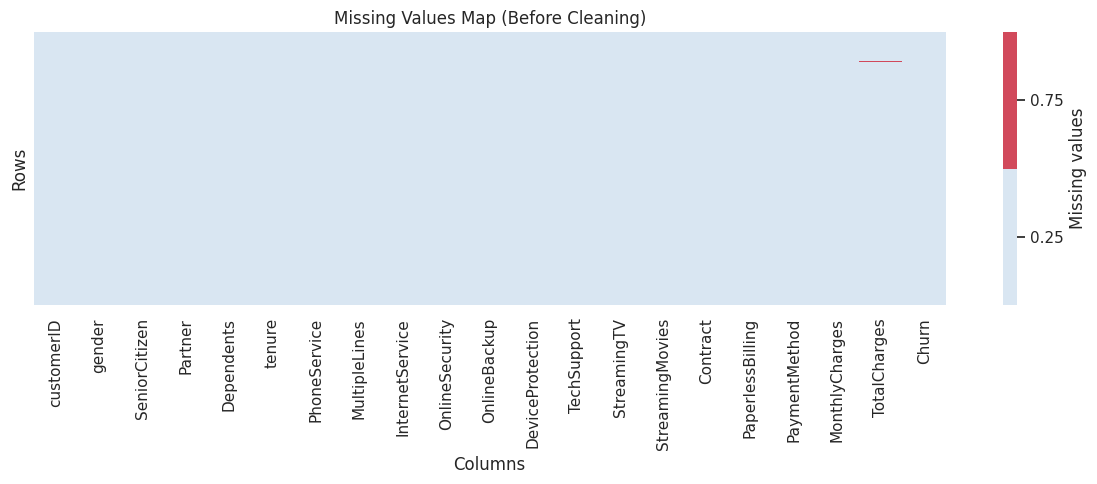

In [11]:

# Missing values map before cleaning
plt.figure(figsize=(12, 5))

r2 = raw.copy()
r2["TotalCharges"] = pd.to_numeric(
    r2["TotalCharges"], errors="coerce"
)

sns.heatmap(
    r2.isnull(),
    cmap=["#d9e6f2", "#d1495b"],
    cbar=True,
    yticklabels=False,
    cbar_kws={
        "ticks": [0.25, 0.75],
        "label": "Missing values"
    }
)

plt.title("Missing Values Map (Before Cleaning)")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.xticks(rotation=90)
plt.tight_layout()

save("w1_fig1_missing")


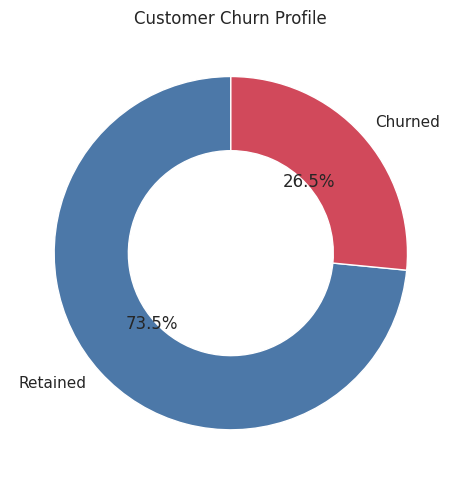

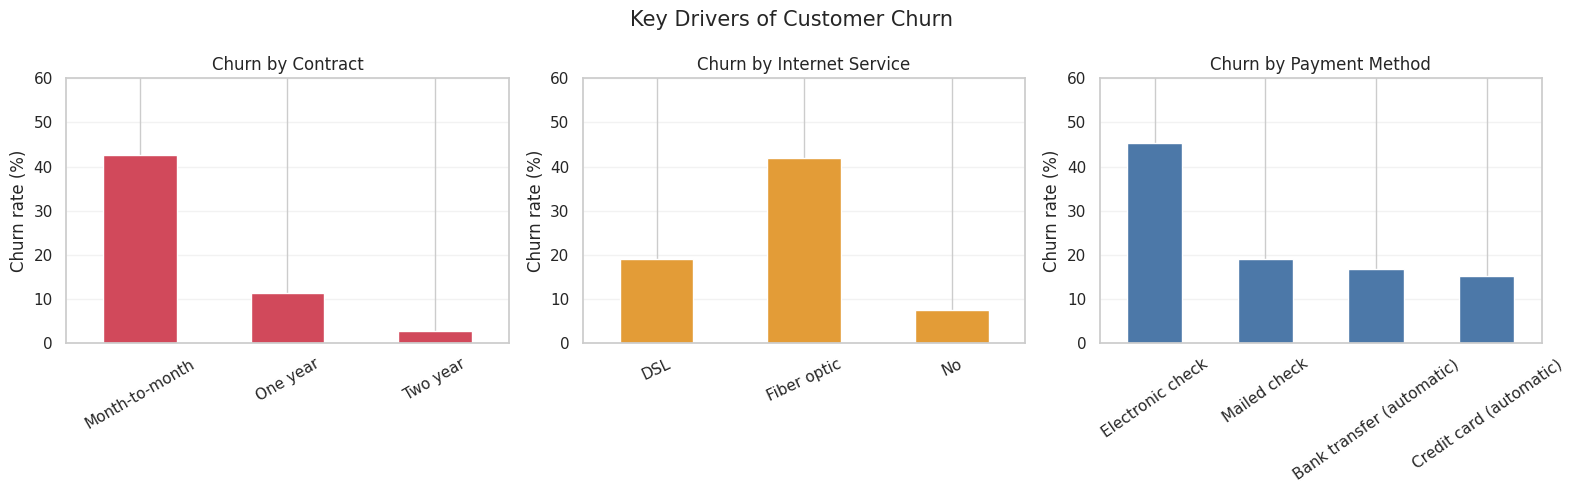

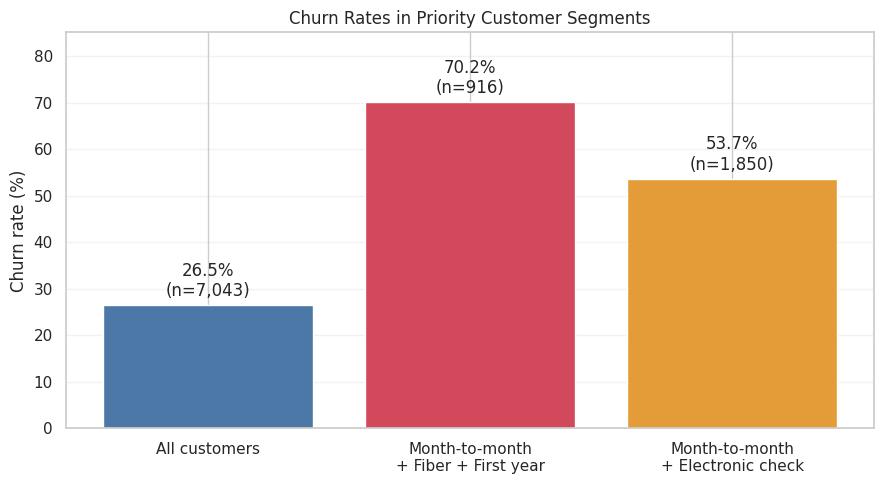

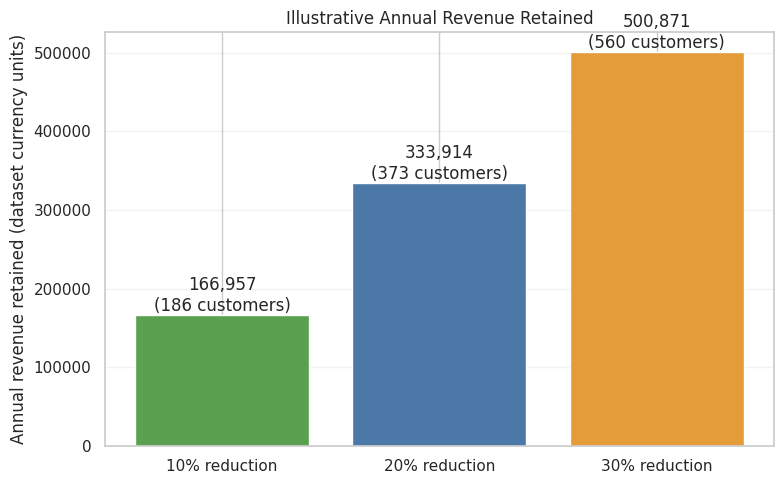

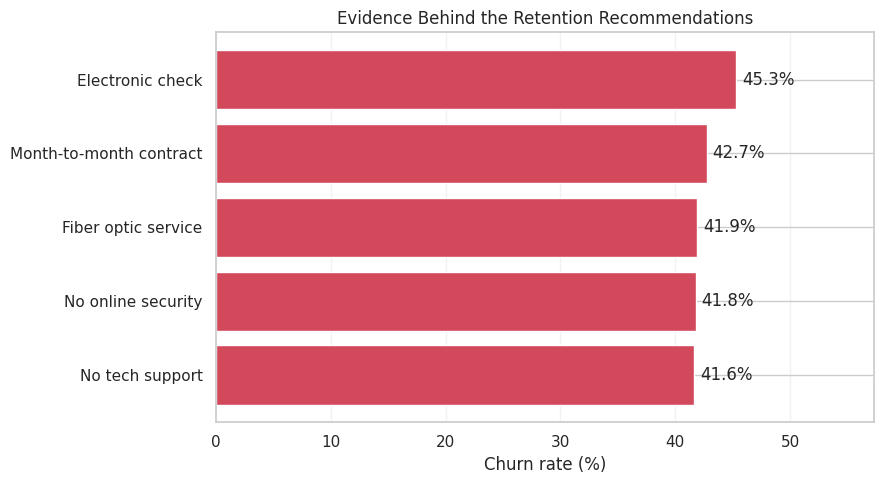

In [13]:

# ============================ WEEK 5 FIGURES ============================

COL = {"Yes": "#d1495b", "No": "#4c78a8"}

# Figure 1: Overall churn profile
plt.figure(figsize=(7, 5))

churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])
plt.pie(
    churn_counts,
    labels=["Retained", "Churned"],
    colors=[COL["No"], COL["Yes"]],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42}
)

plt.title("Customer Churn Profile")
plt.tight_layout()
save("w5_fig1_churn_profile")


# Figure 2: Churn rates by key drivers
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

contract_rate = (
    df.groupby("Contract", observed=False)["Churn_flag"].mean() * 100
).reindex(["Month-to-month", "One year", "Two year"])

internet_rate = (
    df.groupby("InternetService", observed=False)["Churn_flag"].mean() * 100
).reindex(["DSL", "Fiber optic", "No"])

payment_rate = (
    df.groupby("PaymentMethod", observed=False)["Churn_flag"].mean() * 100
).sort_values(ascending=False)

contract_rate.plot(
    kind="bar", ax=ax[0], color="#d1495b"
)
ax[0].set_title("Churn by Contract")
ax[0].set_ylabel("Churn rate (%)")
ax[0].set_xlabel("")
ax[0].tick_params(axis="x", rotation=30)

internet_rate.plot(
    kind="bar", ax=ax[1], color="#e39c37"
)
ax[1].set_title("Churn by Internet Service")
ax[1].set_ylabel("Churn rate (%)")
ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=25)

payment_rate.plot(
    kind="bar", ax=ax[2], color="#4c78a8"
)
ax[2].set_title("Churn by Payment Method")
ax[2].set_ylabel("Churn rate (%)")
ax[2].set_xlabel("")
ax[2].tick_params(axis="x", rotation=35)

for a in ax:
    a.set_ylim(0, 60)
    a.grid(axis="y", alpha=0.25)

fig.suptitle("Key Drivers of Customer Churn", fontsize=15)
plt.tight_layout()
save("w5_fig2_key_drivers")


# Figure 3: High-risk customer segments
segment_names = [
    "All customers",
    "Month-to-month\n+ Fiber + First year",
    "Month-to-month\n+ Electronic check"
]

segment_rates = [
    df["Churn_flag"].mean() * 100,
    seg["Churn_flag"].mean() * 100,
    seg2["Churn_flag"].mean() * 100
]

segment_sizes = [len(df), len(seg), len(seg2)]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    segment_names,
    segment_rates,
    color=["#4c78a8", "#d1495b", "#e39c37"]
)

for bar, rate, size in zip(bars, segment_rates, segment_sizes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.1f}%\n(n={size:,})",
        ha="center",
        va="bottom"
    )

ax.set_title("Churn Rates in Priority Customer Segments")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, max(segment_rates) + 15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
save("w5_fig3_high_risk_segments")


# Figure 4: Potential annual revenue retained
reduction_rates = [10, 20, 30]
churned_customers = int(df["Churn_flag"].sum())
annual_revenue_lost = df.loc[
    df["Churn_flag"] == 1, "MonthlyCharges"
].sum() * 12

customers_retained = [
    int(churned_customers * r / 100)
    for r in reduction_rates
]

revenue_retained = [
    annual_revenue_lost * r / 100
    for r in reduction_rates
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    [f"{r}% reduction" for r in reduction_rates],
    revenue_retained,
    color=["#59a14f", "#4c78a8", "#e39c37"]
)

for bar, revenue, customers in zip(
    bars, revenue_retained, customers_retained
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{revenue:,.0f}\n({customers} customers)",
        ha="center",
        va="bottom"
    )

ax.set_title("Illustrative Annual Revenue Retained")
ax.set_ylabel("Annual revenue retained (dataset currency units)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
save("w5_fig4_revenue_impact")


# Figure 5: Evidence supporting strategic recommendations
recommendation_rates = pd.Series({
    "Month-to-month contract": (
        df.loc[df["Contract"] == "Month-to-month", "Churn_flag"].mean() * 100
    ),
    "Fiber optic service": (
        df.loc[df["InternetService"] == "Fiber optic", "Churn_flag"].mean() * 100
    ),
    "Electronic check": (
        df.loc[df["PaymentMethod"] == "Electronic check", "Churn_flag"].mean() * 100
    ),
    "No tech support": (
        df.loc[
            (df["InternetService"] != "No") &
            (df["TechSupport"] == "No"),
            "Churn_flag"
        ].mean() * 100
    ),
    "No online security": (
        df.loc[
            (df["InternetService"] != "No") &
            (df["OnlineSecurity"] == "No"),
            "Churn_flag"
        ].mean() * 100
    )
}).sort_values()

plt.figure(figsize=(9, 5))

bars = plt.barh(
    recommendation_rates.index,
    recommendation_rates.values,
    color="#d1495b"
)

for bar, rate in zip(bars, recommendation_rates.values):
    plt.text(
        rate + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.1f}%",
        va="center"
    )

plt.title("Evidence Behind the Retention Recommendations")
plt.xlabel("Churn rate (%)")
plt.xlim(0, max(recommendation_rates.values) + 12)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
save("w5_fig5_recommendations")


# WEEK 5: COMPREHENSIVE PROJECT REPORT

**Title:** Reducing Customer Churn: An End-to-End Data Science Report with Strategic Recommendations

## 5. Results and Analysis

### 5.1 Churn Profile

Total customers: 7,043
Churned customers: 1,869
Overall churn rate: 26.54%
Share of churners with tenure <= 12 months: 55.5%


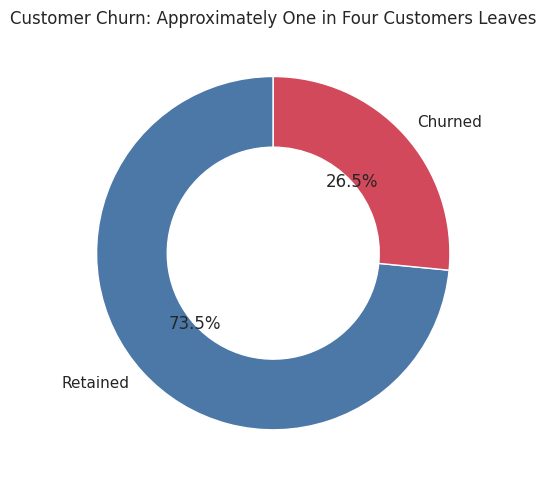

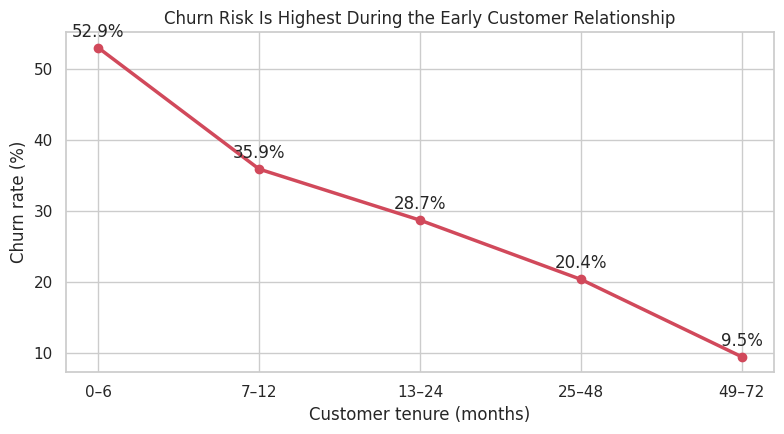


Churn rate by tenure band:
tenure_band
0–6      52.94
7–12     35.89
13–24    28.71
25–48    20.39
49–72     9.51


### 5.2 Contract Effect

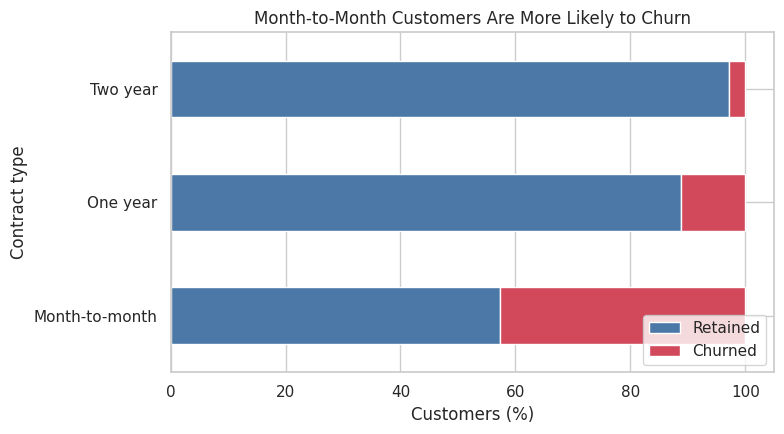

Churn rate by contract type (%):
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83


The contract–churn association can also be examined using the standardized residuals from the Week 3 chi-square test.

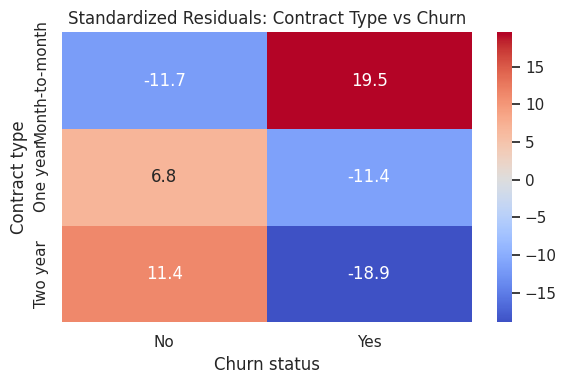

Chi-square = 1184.597, p-value = 5.863e-258


### 5.3 Service and Payment Effects

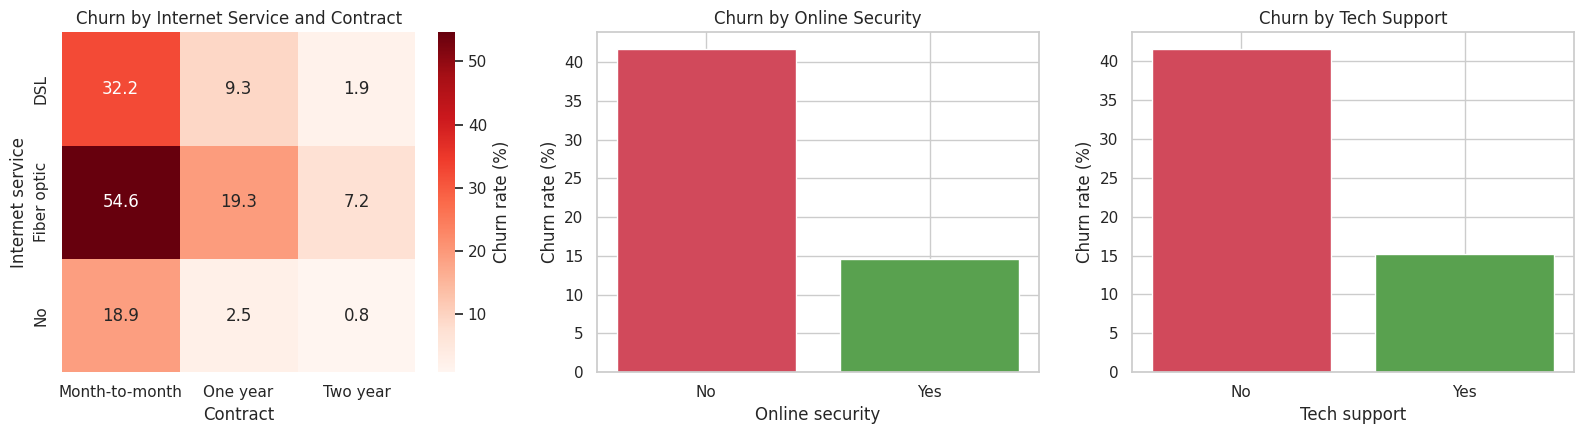

Churn rate by internet service (%):
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn_flag, dtype: float64

Churn rate by payment method (%):
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn_flag, dtype: float64


### 5.4 The Price Question

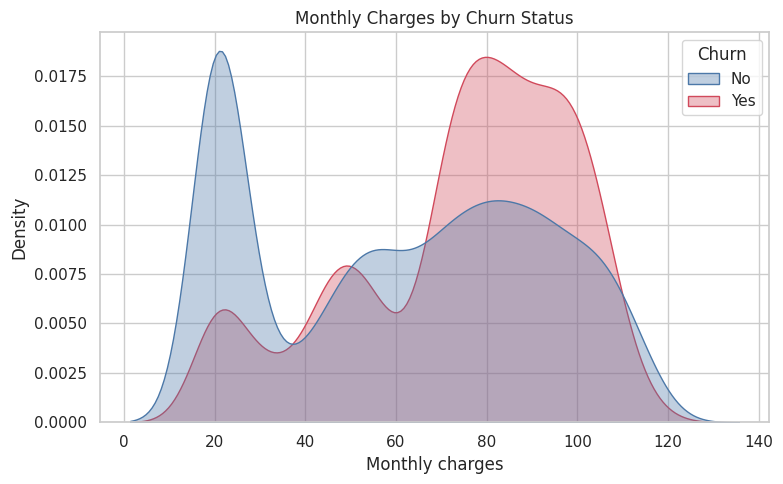

Average monthly charges by churn status:
Churn
No     61.27
Yes    74.44

Average monthly charges among internet customers:
Churn
No     76.34
Yes    77.92


### 5.5 Statistical Evidence

,Analysis,Test statistic,p-value,Effect size
0,Monthly charges by churn,Welch t = 18.41,8.592449e-73,Mean difference
1,Contract type vs churn,Chi-square = 1184.60,5.863038e-258,Cramer's V = 0.41
2,Tenure by contract,ANOVA F = 2960.02,0.000000e+00,Eta-squared = 0.46
3,Payment method vs churn,Chi-square = 648.14,3.682355e-140,Cramer's V = 0.30



Interpretation: compare each p-value with the Bonferroni-adjusted threshold of 0.0125.


### 5.6 Model Performance

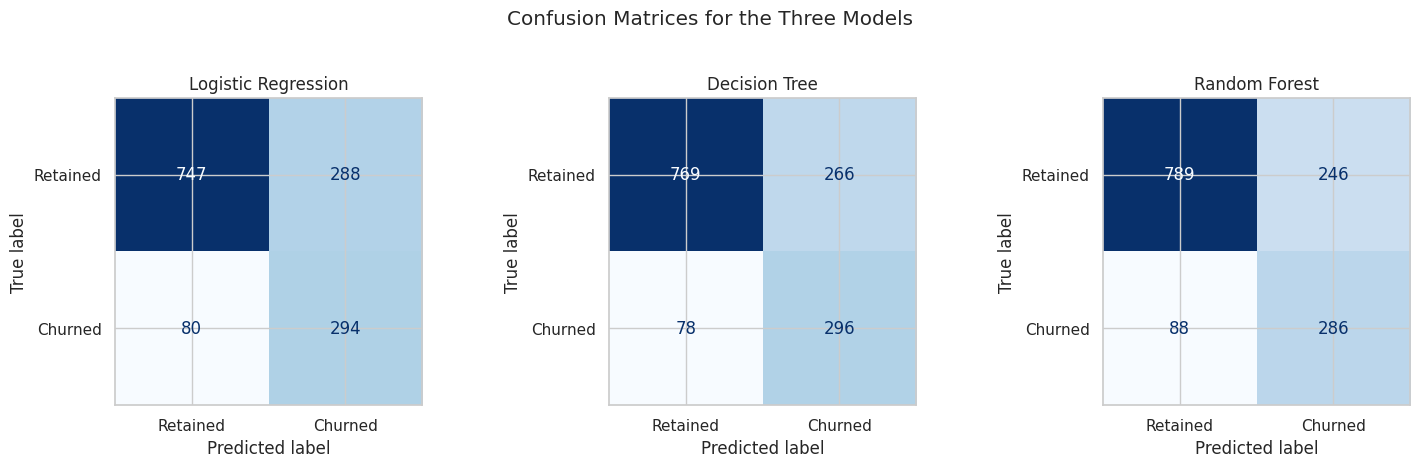

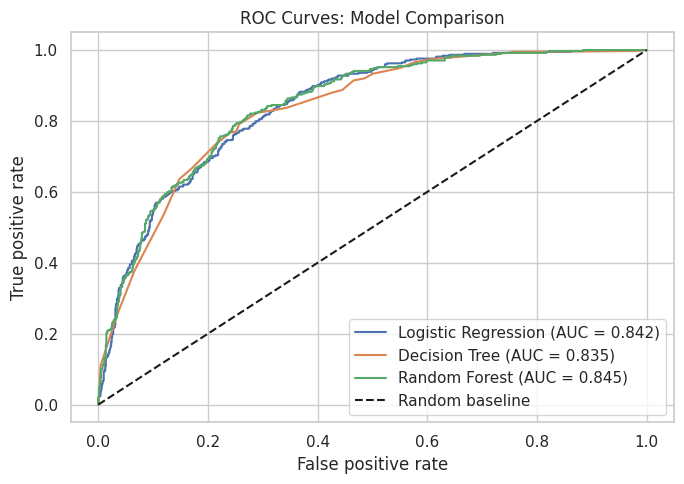

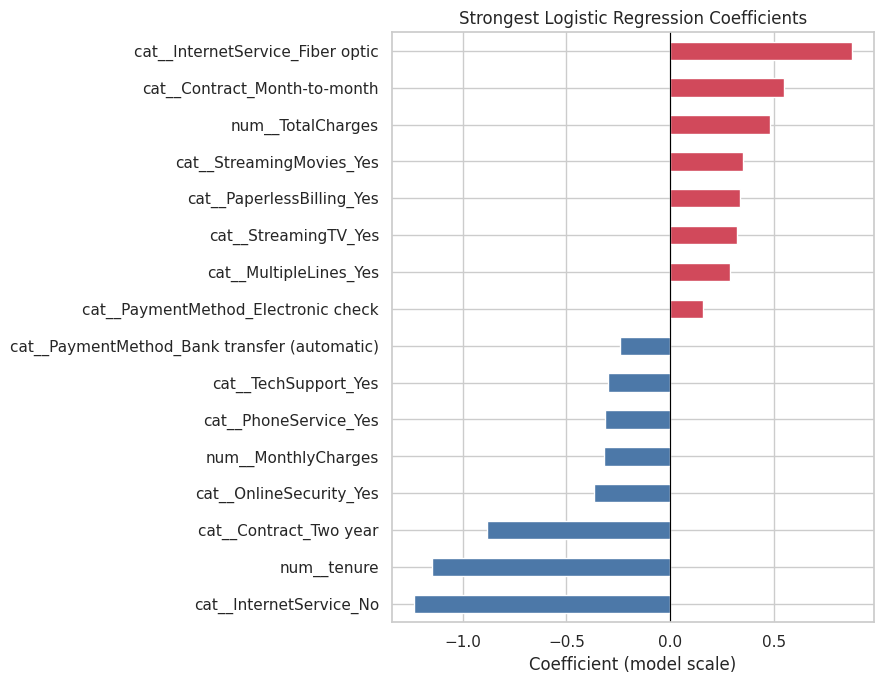

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.739,0.505,0.786,0.615,0.842
1,Decision Tree,0.756,0.527,0.791,0.632,0.835
2,Random Forest,0.763,0.538,0.765,0.631,0.845


### 5.7 Consistency Across Methods

Visualizations, statistical tests, and predictive models can be compared to assess whether they identify similar churn patterns.
Review contract type, tenure, internet service, support services, and payment method across the outputs above.


## 6. Discussion

### 6.1 Interpretation

...

- Run A/B tests to evaluate the causal impact of interventions.

- Build an operational dashboard with risk rankings, monitoring, and scheduled retraining.

## 11. Conclusion

The project took raw public data through cleaning, exploration, statistical validation, and machine learning modelling to produce evidence-based recommendations.

The consistent message across the analyses is that churn is concentrated among newer customers on month-to-month contracts, particularly fiber-optic customers without support services. Price alone is a weak explanation for churn among internet customers.

Promoting longer-term contracts, improving early customer engagement, reviewing fiber-optic service value, and using model-targeted retention offers could help reduce churn. These interventions should be tested through controlled pilots before broad implementation.

The project provides a reproducible analytical process, and each recommendation is paired with a measurable success metric and a plan for evaluation.


WEEK 5 COMPLETE — figures displayed only; no files saved.


In [14]:

# ============================ WEEK 5 ============================
# RESULTS, DISCUSSION, RECOMMENDATIONS AND BUSINESS IMPACT
# Displays figures only; does not save figures or create a ZIP file.

from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

display(Markdown("# WEEK 5: COMPREHENSIVE PROJECT REPORT"))
display(Markdown(
    "**Title:** Reducing Customer Churn: An End-to-End Data Science "
    "Report with Strategic Recommendations"
))

# ------------------------------------------------------------
# SECTION 5: RESULTS AND ANALYSIS
# ------------------------------------------------------------

display(Markdown("## 5. Results and Analysis"))

# 5.1 Churn Profile
display(Markdown("### 5.1 Churn Profile"))

churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])
churn_pct = df["Churn"].value_counts(normalize=True).reindex(["No", "Yes"]) * 100

print(f"Total customers: {len(df):,}")
print(f"Churned customers: {(df['Churn'] == 'Yes').sum():,}")
print(f"Overall churn rate: {df['Churn_flag'].mean() * 100:.2f}%")
print(f"Share of churners with tenure <= 12 months: "
      f"{(df.loc[df['Churn'] == 'Yes', 'tenure'] <= 12).mean() * 100:.1f}%")

# Figure 1: Overall churn profile
plt.figure(figsize=(6, 5))
plt.pie(
    churn_counts,
    labels=["Retained", "Churned"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4c78a8", "#d1495b"],
    wedgeprops={"width": 0.4}
)
plt.title("Customer Churn: Approximately One in Four Customers Leaves")
plt.tight_layout()
plt.show()

# Figure 2: Churn rate by tenure band
tenure_bands = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0–6", "7–12", "13–24", "25–48", "49–72"]
)
tenure_churn = (
    df.assign(tenure_band=tenure_bands)
      .groupby("tenure_band", observed=True)["Churn_flag"]
      .mean() * 100
)

plt.figure(figsize=(8, 4.5))
plt.plot(
    tenure_churn.index.astype(str),
    tenure_churn.values,
    marker="o",
    linewidth=2.5,
    color="#d1495b"
)
for x, y in zip(tenure_churn.index.astype(str), tenure_churn.values):
    plt.annotate(f"{y:.1f}%", (x, y), xytext=(0, 8),
                 textcoords="offset points", ha="center")
plt.title("Churn Risk Is Highest During the Early Customer Relationship")
plt.xlabel("Customer tenure (months)")
plt.ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

print("\nChurn rate by tenure band:")
print(tenure_churn.round(2).to_string())


# 5.2 Contract Effect
display(Markdown("### 5.2 Contract Effect"))

contract_churn = pd.crosstab(
    df["Contract"], df["Churn"], normalize="index"
).mul(100).reindex(
    ["Month-to-month", "One year", "Two year"]
)

plt.figure(figsize=(8, 4.5))
contract_churn[["No", "Yes"]].plot(
    kind="barh",
    stacked=True,
    color=["#4c78a8", "#d1495b"],
    ax=plt.gca()
)
plt.title("Month-to-Month Customers Are More Likely to Churn")
plt.xlabel("Customers (%)")
plt.ylabel("Contract type")
plt.legend(["Retained", "Churned"], loc="lower right")
plt.tight_layout()
plt.show()

print("Churn rate by contract type (%):")
print((df.groupby("Contract")["Churn_flag"].mean() * 100).round(2).to_string())

display(Markdown(
    "The contract–churn association can also be examined using the "
    "standardized residuals from the Week 3 chi-square test."
))

contract_table = pd.crosstab(df["Contract"], df["Churn"])
chi2, p_contract, dof, expected = __import__("scipy").stats.chi2_contingency(
    contract_table
)
residuals = (
    contract_table.to_numpy() - expected
) / np.sqrt(expected)

plt.figure(figsize=(6, 4))
sns.heatmap(
    pd.DataFrame(
        residuals,
        index=contract_table.index,
        columns=contract_table.columns
    ),
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    center=0
)
plt.title("Standardized Residuals: Contract Type vs Churn")
plt.xlabel("Churn status")
plt.ylabel("Contract type")
plt.tight_layout()
plt.show()

print(f"Chi-square = {chi2:.3f}, p-value = {p_contract:.3e}")


# 5.3 Service and Payment Effects
display(Markdown("### 5.3 Service and Payment Effects"))

internet_df = df[df["InternetService"] != "No"].copy()

service_cols = ["OnlineSecurity", "TechSupport"]
service_rates = (
    internet_df.groupby(service_cols[0])["Churn_flag"].mean() * 100
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Churn rate by internet service and contract
service_contract = pd.pivot_table(
    df,
    index="InternetService",
    columns="Contract",
    values="Churn_flag",
    aggfunc="mean"
).mul(100)

sns.heatmap(
    service_contract,
    annot=True,
    fmt=".1f",
    cmap="Reds",
    ax=axes[0],
    cbar_kws={"label": "Churn rate (%)"}
)
axes[0].set_title("Churn by Internet Service and Contract")
axes[0].set_xlabel("Contract")
axes[0].set_ylabel("Internet service")

# Churn by online security
security_rates = (
    internet_df.groupby("OnlineSecurity")["Churn_flag"].mean() * 100
)
axes[1].bar(
    security_rates.index.astype(str),
    security_rates.values,
    color=["#d1495b" if x == "No" else "#59a14f"
           for x in security_rates.index]
)
axes[1].set_title("Churn by Online Security")
axes[1].set_xlabel("Online security")
axes[1].set_ylabel("Churn rate (%)")

# Churn by tech support
support_rates = (
    internet_df.groupby("TechSupport")["Churn_flag"].mean() * 100
)
axes[2].bar(
    support_rates.index.astype(str),
    support_rates.values,
    color=["#d1495b" if x == "No" else "#59a14f"
           for x in support_rates.index]
)
axes[2].set_title("Churn by Tech Support")
axes[2].set_xlabel("Tech support")
axes[2].set_ylabel("Churn rate (%)")

plt.tight_layout()
plt.show()

print("Churn rate by internet service (%):")
print((df.groupby("InternetService")["Churn_flag"].mean() * 100).round(2))
print("\nChurn rate by payment method (%):")
print((df.groupby("PaymentMethod")["Churn_flag"].mean() * 100).round(2))


# 5.4 The Price Question
display(Markdown("### 5.4 The Price Question"))

plt.figure(figsize=(8, 5))
sns.kdeplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    fill=True,
    common_norm=False,
    alpha=0.35,
    palette={"No": "#4c78a8", "Yes": "#d1495b"}
)
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Monthly charges")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

print("Average monthly charges by churn status:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2).to_string())

internet_means = (
    internet_df.groupby("Churn")["MonthlyCharges"].mean().round(2)
)
print("\nAverage monthly charges among internet customers:")
print(internet_means.to_string())


# 5.5 Statistical Evidence
display(Markdown("### 5.5 Statistical Evidence"))

from scipy import stats

# Monthly charges: Welch's t-test
churned_charges = df.loc[df["Churn"] == "Yes", "MonthlyCharges"]
retained_charges = df.loc[df["Churn"] == "No", "MonthlyCharges"]
t_stat, p_value = stats.ttest_ind(
    churned_charges, retained_charges, equal_var=False
)

# Contract type vs churn: chi-square and Cramer's V
contract_table = pd.crosstab(df["Contract"], df["Churn"])
chi2, p_contract, dof, expected = stats.chi2_contingency(contract_table)
cramers_v_contract = np.sqrt(
    chi2 / (contract_table.to_numpy().sum() *
            (min(contract_table.shape) - 1))
)

# Tenure by contract: one-way ANOVA and eta-squared
tenure_groups = [
    group["tenure"].values
    for _, group in df.groupby("Contract", observed=True)
]
f_stat, p_tenure = stats.f_oneway(*tenure_groups)
aov_table = sm.stats.anova_lm(
    ols("tenure ~ C(Contract)", data=df).fit(),
    typ=2
)
eta_squared = (
    aov_table["sum_sq"].iloc[0] / aov_table["sum_sq"].sum()
)

# Payment method vs churn: chi-square and Cramer's V
payment_table = pd.crosstab(df["PaymentMethod"], df["Churn"])
chi2_payment, p_payment, dof_payment, expected_payment = (
    stats.chi2_contingency(payment_table)
)
cramers_v_payment = np.sqrt(
    chi2_payment / (payment_table.to_numpy().sum() *
                    (min(payment_table.shape) - 1))
)

stat_results = pd.DataFrame([
    {
        "Analysis": "Monthly charges by churn",
        "Test statistic": f"Welch t = {t_stat:.2f}",
        "p-value": p_value,
        "Effect size": "Mean difference"
    },
    {
        "Analysis": "Contract type vs churn",
        "Test statistic": f"Chi-square = {chi2:.2f}",
        "p-value": p_contract,
        "Effect size": f"Cramer's V = {cramers_v_contract:.2f}"
    },
    {
        "Analysis": "Tenure by contract",
        "Test statistic": f"ANOVA F = {f_stat:.2f}",
        "p-value": p_tenure,
        "Effect size": f"Eta-squared = {eta_squared:.2f}"
    },
    {
        "Analysis": "Payment method vs churn",
        "Test statistic": f"Chi-square = {chi2_payment:.2f}",
        "p-value": p_payment,
        "Effect size": f"Cramer's V = {cramers_v_payment:.2f}"
    }
])

display(stat_results)
print("\nInterpretation: compare each p-value with the Bonferroni-adjusted "
      "threshold of 0.0125.")


# 5.6 Model Performance
display(Markdown("### 5.6 Model Performance"))

# Uses the trained Week 4 models in `pipes`
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (model_name, model_pipe) in zip(axes, pipes.items()):
    ConfusionMatrixDisplay.from_estimator(
        model_pipe,
        X_te,
        y_te,
        ax=ax,
        cmap="Blues",
        display_labels=["Retained", "Churned"],
        colorbar=False
    )
    ax.set_title(model_name)

plt.suptitle("Confusion Matrices for the Three Models", y=1.03)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
for model_name, model_pipe in pipes.items():
    model_prob = model_pipe.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, model_prob)
    auc = roc_auc_score(y_te, model_prob)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curves: Model Comparison")
plt.legend()
plt.tight_layout()
plt.show()

# Logistic regression coefficient chart
lr = pipes["Logistic Regression"]
feature_names = lr.named_steps["pre"].get_feature_names_out()
coef = pd.Series(
    lr.named_steps["clf"].coef_[0],
    index=feature_names
).sort_values()

coef_to_plot = pd.concat([coef.head(8), coef.tail(8)]).sort_values()

plt.figure(figsize=(9, 7))
coef_to_plot.plot(kind="barh", color=[
    "#d1495b" if value > 0 else "#4c78a8"
    for value in coef_to_plot.values
])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Strongest Logistic Regression Coefficients")
plt.xlabel("Coefficient (model scale)")
plt.tight_layout()
plt.show()

# Print model metrics
metric_rows = []
for model_name, model_pipe in pipes.items():
    predictions = model_pipe.predict(X_te)
    probabilities = model_pipe.predict_proba(X_te)[:, 1]
    metric_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_te, predictions),
        "Precision": precision_score(y_te, predictions, zero_division=0),
        "Recall": recall_score(y_te, predictions, zero_division=0),
        "F1-score": f1_score(y_te, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_te, probabilities)
    })

display(pd.DataFrame(metric_rows).round(3))


# 5.7 Consistency Across Methods
display(Markdown("### 5.7 Consistency Across Methods"))

print(
    "Visualizations, statistical tests, and predictive models can be compared "
    "to assess whether they identify similar churn patterns."
)
print(
    "Review contract type, tenure, internet service, support services, "
    "and payment method across the outputs above."
)


# ------------------------------------------------------------
# SECTION 6: DISCUSSION
# ------------------------------------------------------------

display(Markdown("## 6. Discussion"))

display(Markdown("### 6.1 Interpretation"))

churned_df = df[df["Churn"] == "Yes"]
month_to_month_churners = churned_df[
    churned_df["Contract"] == "Month-to-month"
]
early_churners = churned_df[churned_df["tenure"] <= 12]
fiber_churners = churned_df[
    churned_df["InternetService"] == "Fiber optic"
]
electronic_churners = churned_df[
    churned_df["PaymentMethod"] == "Electronic check"
]

print(f"Month-to-month customers among churners: "
      f"{len(month_to_month_churners) / len(churned_df) * 100:.1f}%")
print(f"Churners with tenure <= 12 months: "
      f"{len(early_churners) / len(churned_df) * 100:.1f}%")
print(f"Fiber-optic customers among churners: "
      f"{len(fiber_churners) / len(churned_df) * 100:.1f}%")
print(f"Electronic check users among churners: "
      f"{len(electronic_churners) / len(churned_df) * 100:.1f}%")

high_risk_segment = df[
    (df["Contract"] == "Month-to-month") &
    (df["InternetService"] == "Fiber optic") &
    (df["tenure"] <= 12)
]
print(f"\nHigh-risk segment size: {len(high_risk_segment)}")
print(f"High-risk segment churn rate: "
      f"{high_risk_segment['Churn_flag'].mean() * 100:.1f}%")

display(Markdown("### 6.2 Unexpected Results"))

print("Churn rate by gender (%):")
print((df.groupby("gender")["Churn_flag"].mean() * 100).round(2))
print("\nChurn rate by internet service (%):")
print((df.groupby("InternetService")["Churn_flag"].mean() * 100).round(2))
print("\nAverage monthly charges among internet customers:")
print(internet_means.to_string())

display(Markdown("### 6.3 Caution"))

print(
    "These results show associations, not proof of causation. "
    "Correlated predictors may affect individual model coefficients, "
    "and retention interventions should be validated through controlled pilots."
)


# ------------------------------------------------------------
# SECTION 7: STRATEGIC RECOMMENDATIONS
# ------------------------------------------------------------

display(Markdown("## 7. Strategic Recommendations"))

recommendations = [
    (
        "1. Move Month-to-Month Customers to Longer Contracts",
        "Offer discounts, free months, or device upgrades for switching "
        "to one-year or two-year contracts. Compare churn among converted "
        "customers with a control group."
    ),
    (
        "2. Invest in the First-Year Customer Experience",
        "Introduce structured onboarding and check-ins at one, three, "
        "and six months. Track churn during the first 12 months."
    ),
    (
        "3. Investigate Fiber-Optic Service Value",
        "Review network quality, outages, speed complaints, and pricing. "
        "Prioritize first-year month-to-month fiber customers for a pilot."
    ),
    (
        "4. Bundle and Promote Protective Services",
        "Test free trials of tech support and online security for new "
        "internet customers using an A/B test."
    ),
    (
        "5. Encourage Automatic Payment",
        "Test a small bill credit for enrolling in automatic card or "
        "bank payments, and monitor changes in churn."
    ),
    (
        "6. Deploy the Model for Targeted Retention",
        "Score customers periodically and target retention offers based "
        "on risk scores and the cost of each offer."
    ),
    (
        "7. Measure, Pilot, Iterate, and Avoid Blanket Price Cuts",
        "Run randomized pilots, monitor churn and offer costs, retrain "
        "the model, and avoid general price cuts unless testing supports them."
    )
]

for heading, action in recommendations:
    display(Markdown(f"### {heading}\n{action}"))

display(Markdown("### How the Recommendations Drive Decisions"))
print(
    "Focus retention spending on month-to-month and early-tenure customers; "
    "investigate fiber-optic service value; test contract, service, and "
    "payment incentives; and use model risk rankings to prioritize outreach."
)


# ------------------------------------------------------------
# SECTION 8: POTENTIAL BUSINESS IMPACT
# ------------------------------------------------------------

display(Markdown("## 8. Potential Business Impact"))

churned_customers = df[df["Churn"] == "Yes"]
monthly_revenue_lost = churned_customers["MonthlyCharges"].sum()
annual_revenue_lost = monthly_revenue_lost * 12

print(f"Customers who churned: {len(churned_customers):,}")
print(f"Monthly recurring revenue represented: {monthly_revenue_lost:,.2f}")
print(f"Annualized recurring revenue represented: {annual_revenue_lost:,.2f}")
print(
    "\nNote: these estimates use the sum of MonthlyCharges for churned "
    "customers as a proxy for revenue at risk."
)

impact_rows = []
for reduction in [0.10, 0.20, 0.30]:
    impact_rows.append({
        "Reduction in churners": f"{reduction:.0%}",
        "Customers retained (approx.)": int(len(churned_customers) * reduction),
        "Annual revenue retained (approx.)": annual_revenue_lost * reduction
    })

display(pd.DataFrame(impact_rows).style.format({
    "Annual revenue retained (approx.)": "{:,.0f}"
}))

display(Markdown(
    "Net benefit equals the revenue retained minus the cost of retention "
    "offers. The estimates are illustrative scenarios, not forecasts."
))


# ------------------------------------------------------------
# SECTION 9: LIMITATIONS
# ------------------------------------------------------------

display(Markdown("## 9. Limitations"))

limitations = [
    "The dataset is observational and represents a single snapshot, so causal conclusions cannot be established.",
    "The data covers one company over an unspecified period, which limits certainty about generalization.",
    "Usage, support complaints, network quality, and competitor offers are not included.",
    "Class imbalance affects precision, and model performance should be tested on future data.",
    "Correlated variables may make individual model coefficients difficult to interpret.",
    "Some features should be checked for possible information leakage before deployment.",
    "Revenue scenarios are illustrative and depend on retention-offer costs and customer behaviour."
]

for item in limitations:
    display(Markdown(f"- {item}"))


# ------------------------------------------------------------
# SECTION 10: FUTURE IMPROVEMENTS
# ------------------------------------------------------------

display(Markdown("## 10. Future Improvements"))

future_work = [
    "Add richer data, including service usage, support tickets, network quality, and competitor pricing.",
    "Test gradient boosting models with hyperparameter tuning and probability calibration.",
    "Use SHAP values to explain predictions for individual customers.",
    "Apply survival analysis to estimate when customers are likely to leave.",
    "Incorporate customer lifetime value when prioritizing retention resources.",
    "Use uplift modelling to identify customers likely to respond to retention offers.",
    "Run A/B tests to evaluate the causal impact of interventions.",
    "Build an operational dashboard with risk rankings, monitoring, and scheduled retraining."
]

for item in future_work:
    display(Markdown(f"- {item}"))


# ------------------------------------------------------------
# SECTION 11: CONCLUSION
# ------------------------------------------------------------

display(Markdown("## 11. Conclusion"))

display(Markdown(
    "The project took raw public data through cleaning, exploration, "
    "statistical validation, and machine learning modelling to produce "
    "evidence-based recommendations.\n\n"
    "The consistent message across the analyses is that churn is concentrated "
    "among newer customers on month-to-month contracts, particularly fiber-optic "
    "customers without support services. Price alone is a weak explanation "
    "for churn among internet customers.\n\n"
    "Promoting longer-term contracts, improving early customer engagement, "
    "reviewing fiber-optic service value, and using model-targeted retention "
    "offers could help reduce churn. These interventions should be tested "
    "through controlled pilots before broad implementation.\n\n"
    "The project provides a reproducible analytical process, and each "
    "recommendation is paired with a measurable success metric and a plan "
    "for evaluation."
))

print("\nWEEK 5 COMPLETE — figures displayed only; no files saved.")
